In [1]:
import pandas as pd
import numpy as np
import missingno as msno
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
path = r'../../data/limpieza/cleaned_data.csv'
df = pd.read_csv(path, header=0)
df

,Unnamed: 0,timestamp,open_binance,high_binance,low_binance,close_binance,volume_binance,trades_binance,volumen_binance,SMA_50_binance,...,volatilidad_200_dxy,momentum_50_dxy,momentum_200_dxy,var_diaria_dxy,rango_dia_dxy,RSI_dxy,pct_cambio_7d,tendencia_futura_7d,pct_cambio_30d,tendencia_futura_30d
0,5171,2023-03-01,23141.57,24000.00,23020.03,23628.97,315287.41737,9390487.0,7.449917e+09,22679.9494,...,3.608698,1.240005,-1.456662,-0.371888,1.000000,61.023720,-4.381577,-1,7.835372,1
1,5172,2023-03-02,23629.76,23796.93,23195.90,23465.32,239315.45219,7435815.0,5.615614e+09,22790.3906,...,3.611084,1.839996,-1.213336,0.526412,0.790001,69.306908,-6.000538,-1,8.496134,1
2,5173,2023-03-03,23465.32,23476.95,21971.13,22354.34,319954.19785,8214639.0,7.152365e+09,22860.5450,...,3.615337,2.269997,-2.030006,-0.485578,0.510002,59.321975,-6.874378,-1,9.543986,1
3,5174,2023-03-04,22354.34,22410.00,22157.08,22346.57,121257.38132,4169260.0,2.709687e+09,22908.8762,...,3.619720,2.263334,-2.036669,-0.054216,0.516668,57.440711,-7.575719,-1,10.506276,1
4,5175,2023-03-05,22346.57,22662.09,22189.22,22430.24,154841.75786,4835978.0,3.473138e+09,22938.3826,...,3.624319,2.159167,-2.163335,-0.054245,0.523333,55.534314,-7.198816,-1,11.489685,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
737,5908,2025-03-07,89931.88,91283.02,84667.03,86801.75,57980.35713,9510442.0,5.032796e+09,96830.4536,...,2.870296,-1.559998,2.010002,-0.689589,0.610001,30.088413,-7.069163,-1,-10.060273,-1
738,5909,2025-03-08,86801.74,86897.25,85218.47,86222.45,12989.23054,2553974.0,1.119963e+09,96473.3530,...,2.870296,-1.559998,2.010002,-0.689589,0.610001,30.088413,-7.396003,-1,-9.980073,-1
739,5910,2025-03-09,86222.46,86500.00,80000.00,80734.37,26115.39345,5189138.0,2.108410e+09,95996.9158,...,2.870296,-1.559998,2.010002,-0.689589,0.610001,30.088413,-5.030962,-1,-9.626627,-1
740,5911,2025-03-10,80734.48,84123.46,77459.91,78595.86,47633.38405,8701538.0,3.743787e+09,95542.2016,...,2.870296,-1.559998,2.010002,-0.689589,0.610001,30.088413,-2.922354,-1,-9.068330,-1


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 742 entries, 0 to 741
Data columns (total 95 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Unnamed: 0                   742 non-null    int64  
 1   timestamp                    742 non-null    object 
 2   open_binance                 742 non-null    float64
 3   high_binance                 742 non-null    float64
 4   low_binance                  742 non-null    float64
 5   close_binance                742 non-null    float64
 6   volume_binance               742 non-null    float64
 7   trades_binance               742 non-null    float64
 8   volumen_binance              742 non-null    float64
 9   SMA_50_binance               742 non-null    float64
 10  SMA_200_binance              742 non-null    float64
 11  EMA_50_binance               742 non-null    float64
 12  EMA_200_binance              742 non-null    float64
 13  var_diaria_binance  

## 1. Conteo de nulos

<Axes: >

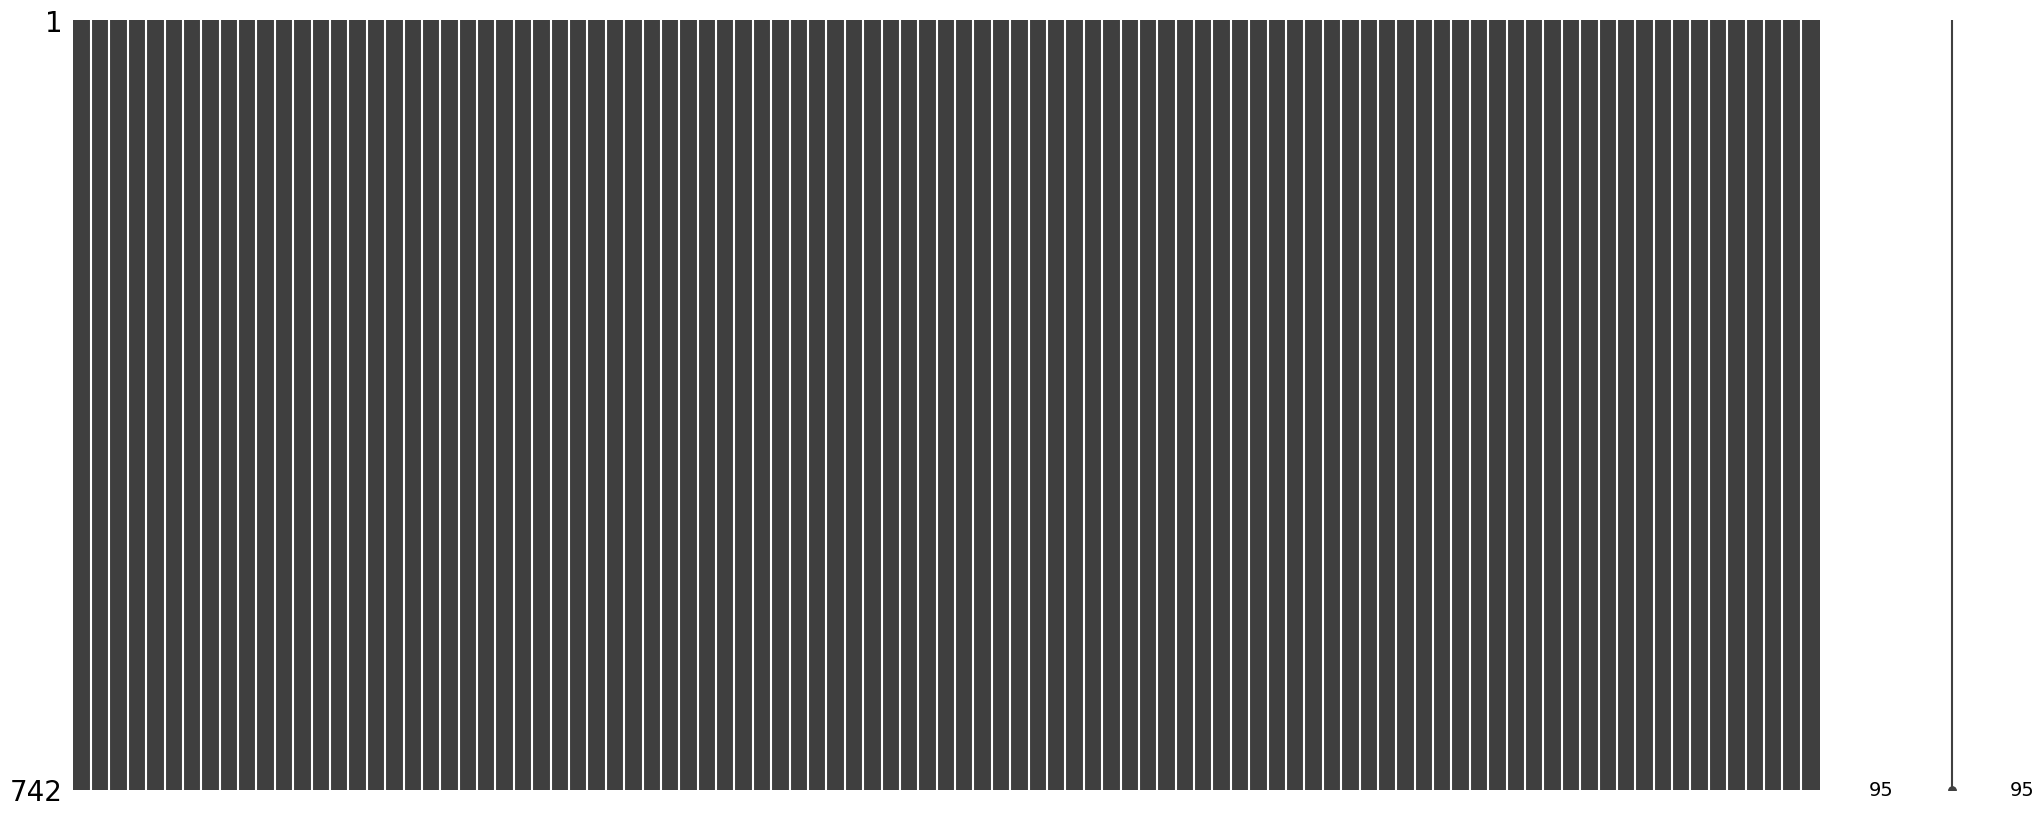

In [4]:
msno.matrix(df)

## 2. Correlaciones

### Relación precios de Bitcoin con otros activos (S&P 500, DXY, Nasdaq)

In [5]:
corr_matrix = df[['open_binance', 'high_binance', 'low_binance', 'close_binance', 'volume_binance', 'trades_binance',
                 'Close_sp500', 'High_sp500', 'Low_sp500', 'Open_sp500', 'Volume_sp500',
                 'Close_nasdaq', 'High_nasdaq', 'Low_nasdaq', 'Open_nasdaq', 'Volume_nasdaq',
                 'Close_dxy', 'High_dxy', 'Low_dxy', 'Open_dxy']].dropna().corr(method='pearson')

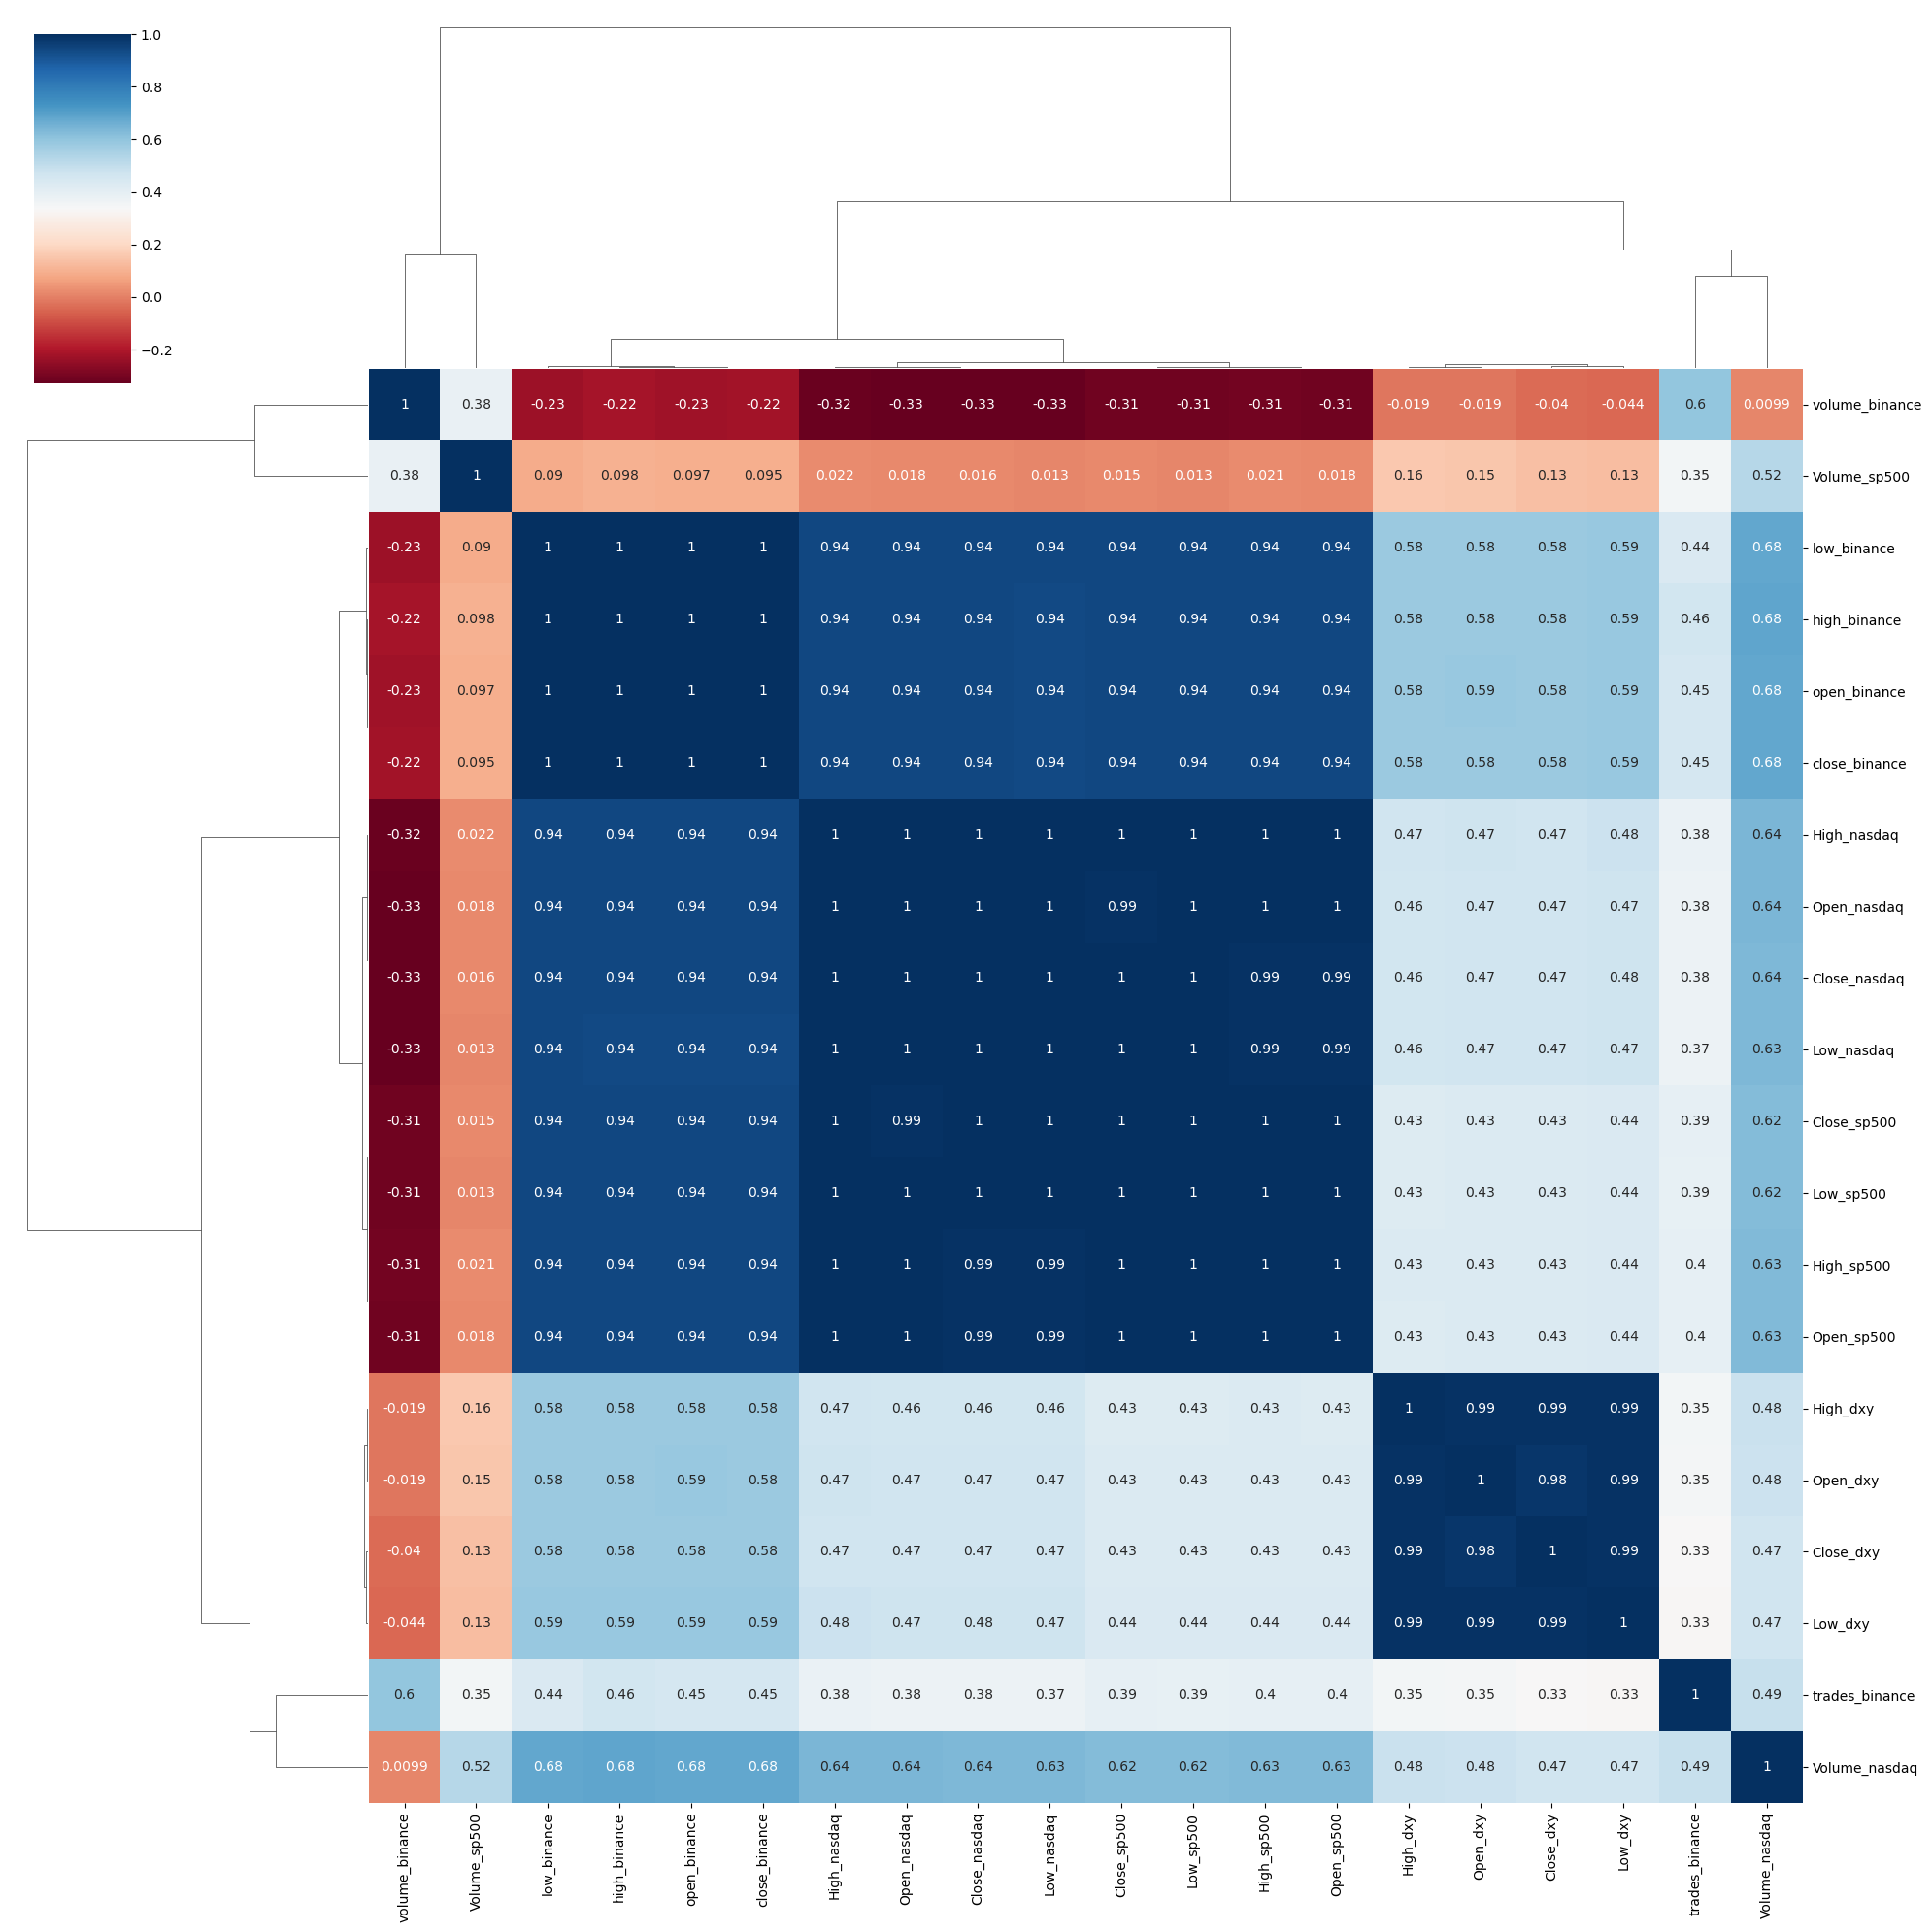

In [6]:
# Aplicar clustermap de la correlación
g = sns.clustermap(corr_matrix, 
                   method='complete',  # Método de enlace para la jerarquía
                   cmap='RdBu',         # Colormap
                   annot=True,          # Mostrar los valores de correlación en el mapa
                   annot_kws={'size': 10}, # Tamaño de la fuente de las anotaciones
                   figsize=(20, 20))     # Tamaño de la figura

# Mostrar el gráfico
plt.show()

### Tendencias en sentimientos del mercado (Fear & Greed Index, Google Trends)

In [7]:
corr_matrix = df[["close_binance", "volatilidad_50_binance", "volatilidad_200_binance", "var_diaria_binance",
                  "fear_greed_index_fg", "bitcoin_gtrends",
                  "Close_sp500", "Close_nasdaq", "Close_dxy"]].dropna().corr(method='spearman')

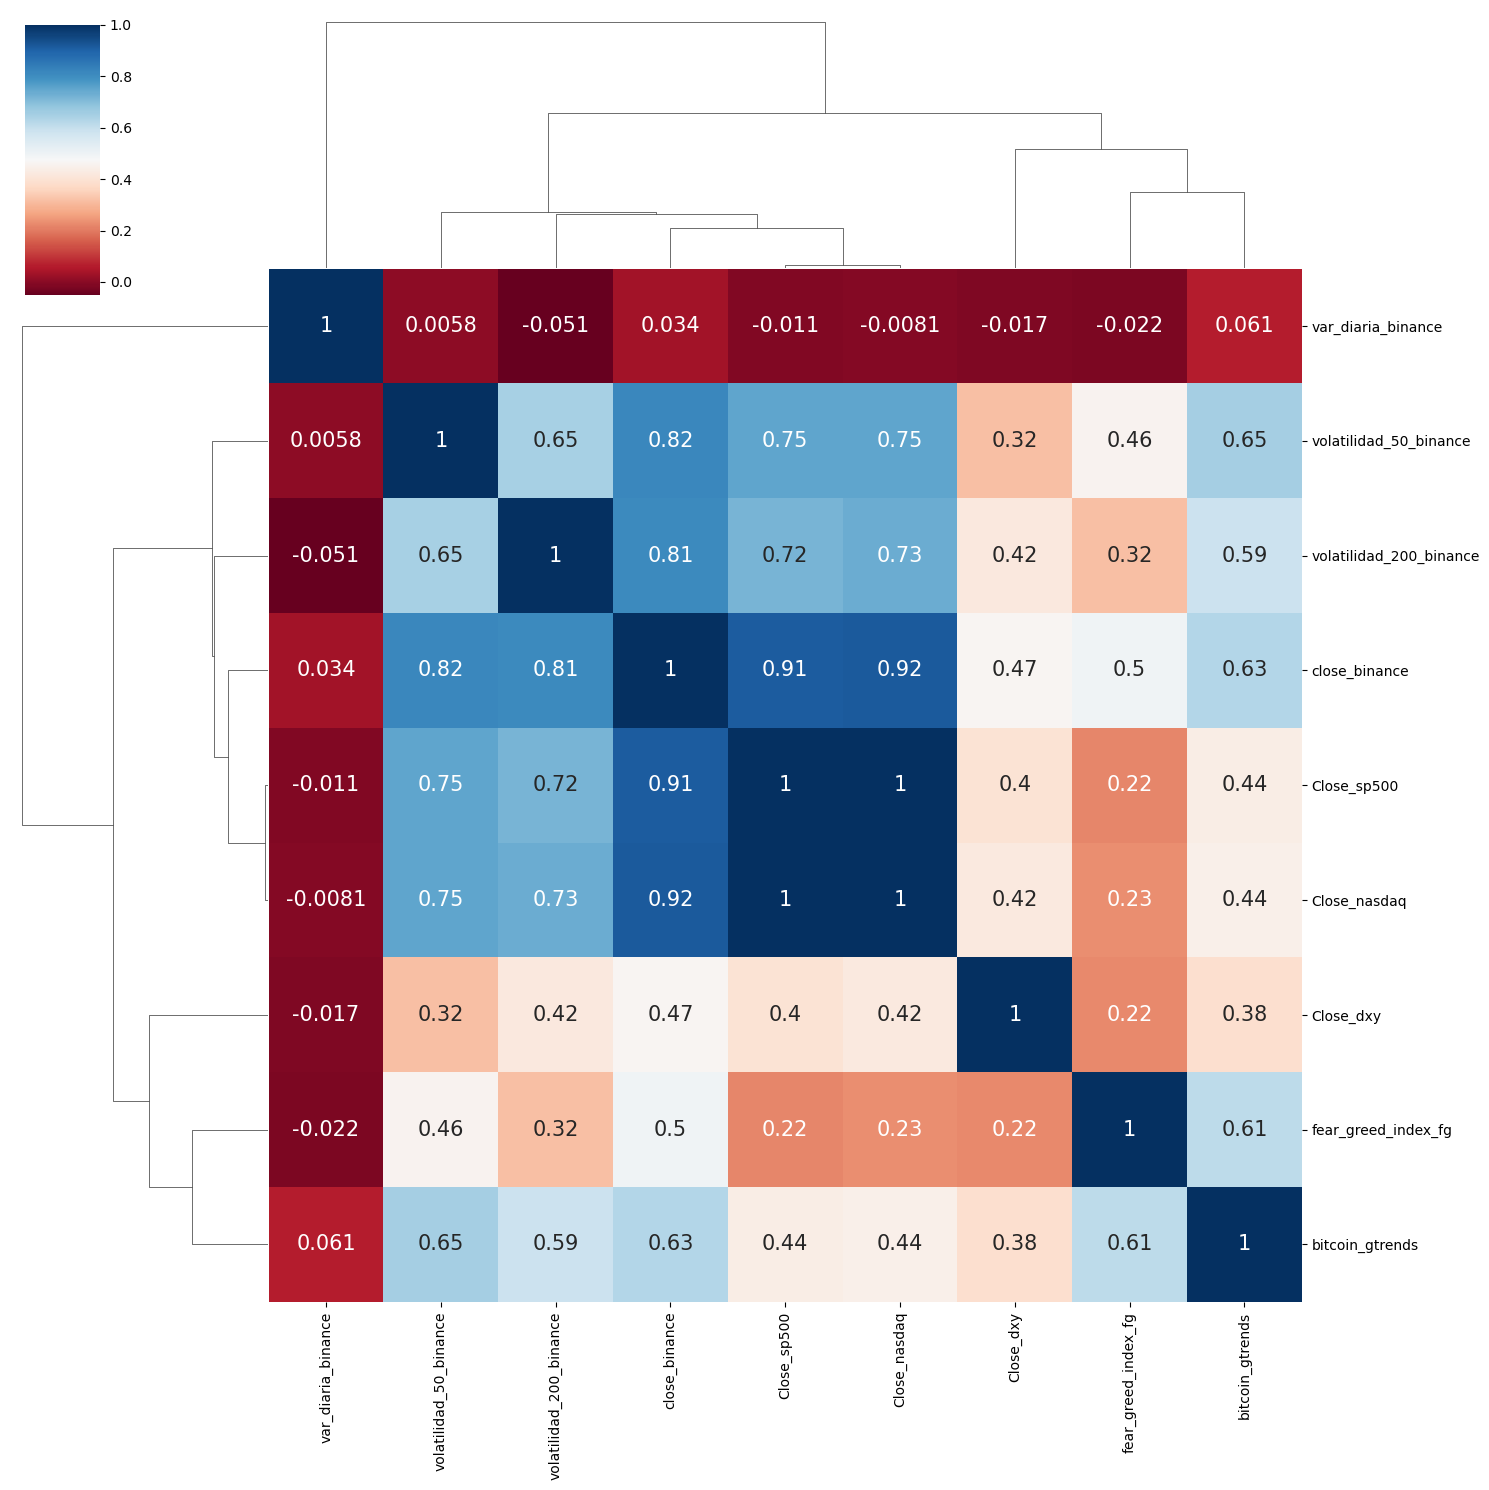

In [8]:
# Aplicar clustermap de la correlación
g = sns.clustermap(corr_matrix, 
                   method='complete',  # Método de enlace para la jerarquía
                   cmap='RdBu',         # Colormap
                   annot=True,          # Mostrar los valores de correlación en el mapa
                   annot_kws={'size': 15}, # Tamaño de la fuente de las anotaciones
                   figsize=(15, 15))     # Tamaño de la figura

# Mostrar el gráfico
plt.show()

### Relación entre volatilidad y precio

In [9]:
df_filtered = df[['close_binance', 'volatilidad_50_binance', 'volatilidad_200_binance', 'var_diaria_binance']].dropna()

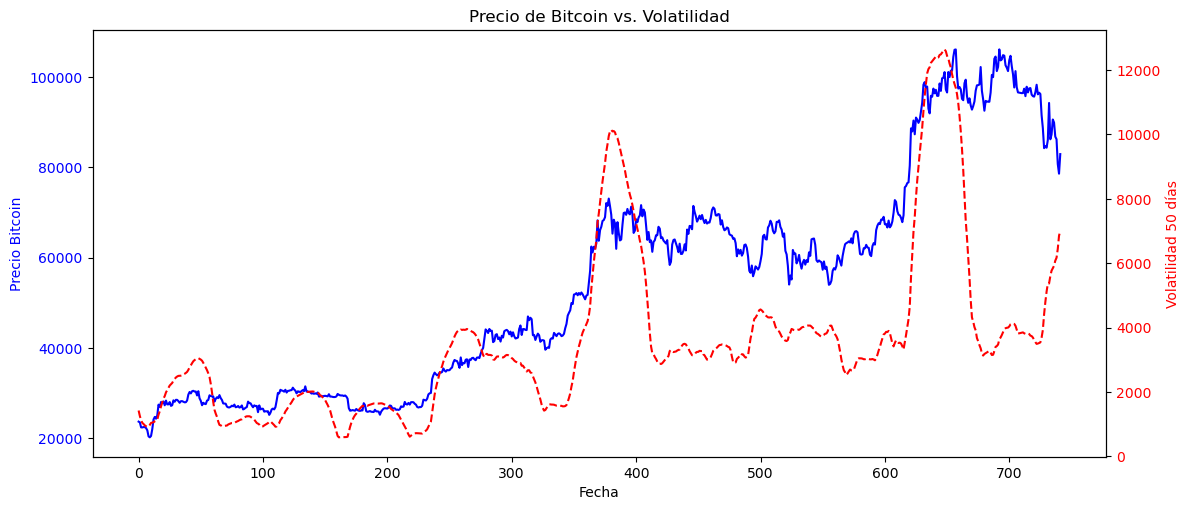

In [10]:
fig, ax1 = plt.subplots(figsize=(12, 5))

# Gráfica de precio (eje izquierdo)
ax1.set_xlabel('Fecha')
ax1.set_ylabel('Precio Bitcoin', color='blue')
ax1.plot(df_filtered.index, df_filtered['close_binance'], color='blue', label='Precio BTC')
ax1.tick_params(axis='y', labelcolor='blue')

# Agregar segundo eje Y para volatilidad
ax2 = ax1.twinx()
ax2.set_ylabel('Volatilidad 50 días', color='red')
ax2.plot(df_filtered.index, df_filtered['volatilidad_50_binance'], color='red', linestyle='dashed', label='Volatilidad 50 días')
ax2.tick_params(axis='y', labelcolor='red')

fig.tight_layout()
plt.title("Precio de Bitcoin vs. Volatilidad")
plt.show()

In [11]:
corr_matrix = df_filtered.corr(method='spearman')  # Spearman capta relaciones no lineales

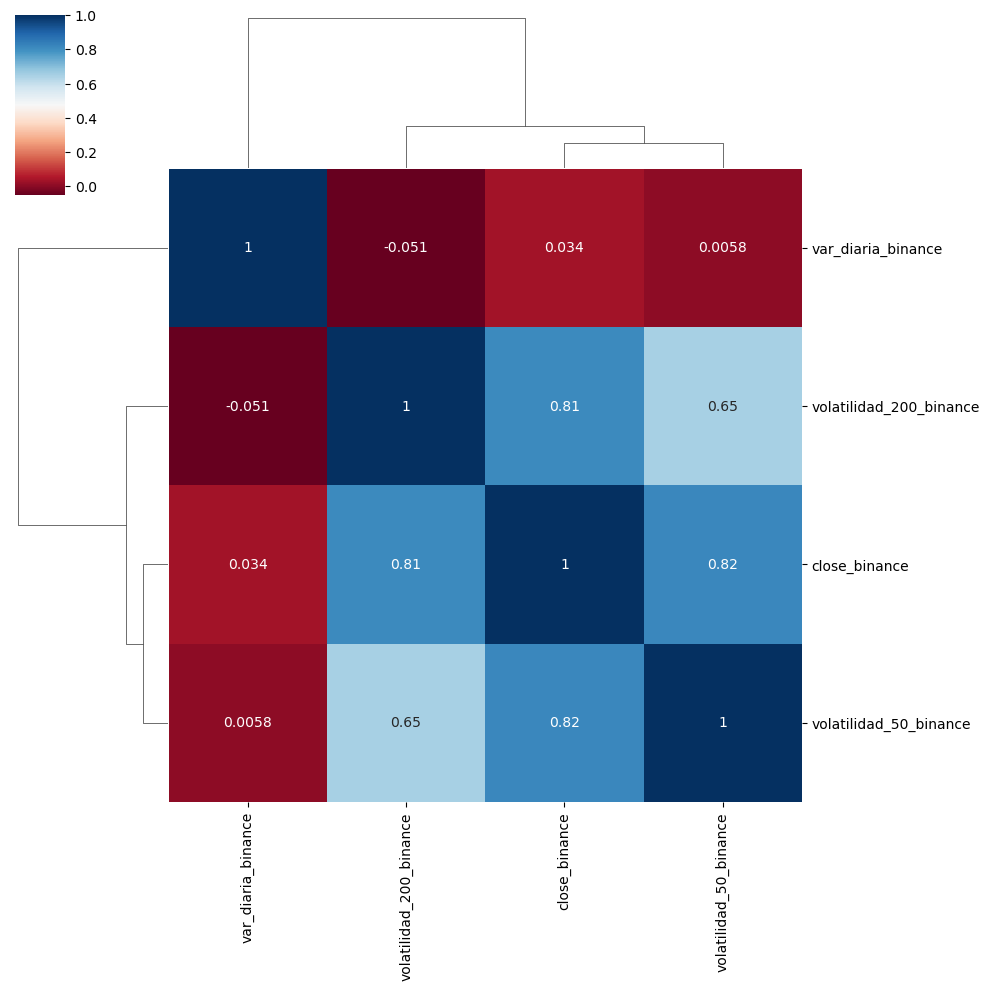

In [12]:
# Aplicar clustermap de la correlación
g = sns.clustermap(corr_matrix, 
                   method='complete',  # Método de enlace para la jerarquía
                   cmap='RdBu',         # Colormap
                   annot=True,          # Mostrar los valores de correlación en el mapa
                   annot_kws={'size': 10}, # Tamaño de la fuente de las anotaciones
                   figsize=(10, 10))     # Tamaño de la figura

# Mostrar el gráfico
plt.show()